# 1D Spectral analysis

In this tutorial, we present the basics steps for a 1D spectral analysis. The main aim is to perform a spectral analysis of a point-like source. A spectral analysis consist in stacking all events in the region of interest. Doing this we forget about the spatial information of the source. This is why the 1D analysis is best suited for point-like sources. 

To estimate the background, we will use off regions taken on the data using reflected regions. 

## 1. Crab Nebula

### 1.1 Full containment IRFs: H.E.S.S. data

We are going to analyse the data from the High Energy Stereoscopic System (H.E.S.S.) towards the Crab nebula.  

Let's start with some basic imports:

In [75]:
from gammapy.data import DataStore
from gammapy.maps import MapAxis, RegionGeom, WcsGeom
from gammapy.makers import SpectrumDatasetMaker, ReflectedRegionsBackgroundMaker, SafeMaskMaker, WobbleRegionsFinder
from gammapy.datasets import SpectrumDataset, Datasets
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel, ExpCutoffPowerLawSpectralModel, LogParabolaSpectralModel
from gammapy.modeling.selection import select_nested_models
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator
from gammapy.visualization import plot_spectrum_datasets_off_regions

from astropy.coordinates import SkyCoord
import astropy.units as u
from regions import CircleSkyRegion, PointSkyRegion

import matplotlib.pyplot as plt
import numpy as np

Create a DataStore instance using the following path to H.E.S.S. data: `$GAMMAPY_DATA/hess-dl3-dr1`.

In [76]:
data_store = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1")

Get the Crab coordinates using astropy `SkyCoord`.

In [77]:
target_position = SkyCoord.from_name("Crab")

To select the relevant runs, we can use the `obs_table` associated to the `DataStore`.

In [78]:
obs_table = data_store.obs_table

Using `select_sky_circle` method of `obs_table`, select run that are at most at 2.2 deg from the Crab Nebula.

In [79]:
obs_table = obs_table.select_sky_circle(target_position, 2.2*u.deg)

We can then get the observations using the `get_observations` method of `DataStore`.

In [80]:
observations = data_store.get_observations(obs_table["OBS_ID"])

In [81]:
print(observations)

Observations
Number of observations: 4
Observation

	obs id            : 23523 
 	tstart            : 53343.92
	tstop             : 53343.94
	duration          : 1687.00 s
	pointing (icrs)   : 83.6 deg, 21.5 deg

	deadtime fraction : 6.2%
Observation

	obs id            : 23526 
 	tstart            : 53343.95
	tstop             : 53343.97
	duration          : 1683.00 s
	pointing (icrs)   : 83.6 deg, 22.5 deg

	deadtime fraction : 6.6%
Observation

	obs id            : 23559 
 	tstart            : 53345.96
	tstop             : 53345.98
	duration          : 1686.00 s
	pointing (icrs)   : 85.3 deg, 22.0 deg

	deadtime fraction : 6.4%
Observation

	obs id            : 23592 
 	tstart            : 53347.91
	tstop             : 53347.93
	duration          : 1686.00 s
	pointing (icrs)   : 82.0 deg, 22.0 deg

	deadtime fraction : 6.2%



Define a energy axis using `MapAxis.from_energy_bounds` between 0.1 and 40 TeV. 

Then define a relevant true energy axis. Remember that the true energy axis should have more bins that the reco energy axis and over a wider range. 

In [82]:
energy_axis = MapAxis.from_energy_bounds(0.1, 40, 10, per_decade=True, unit="TeV")

energy_axis_true = MapAxis.from_energy_bounds(
    0.01, 100, 20, unit="TeV", name="energy_true", per_decade=True
)

Define a region of interest:

In [83]:
on_region = CircleSkyRegion(target_position, 0.1*u.deg)

For the crab, we have to create a exclusion mask for a star that is in the same field of view

In [84]:
exclusion_region = CircleSkyRegion(
    center=SkyCoord(183.604, -8.708, unit="deg", frame="galactic"),
    radius=0.5 * u.deg,
)

Plot the exclusion mask:

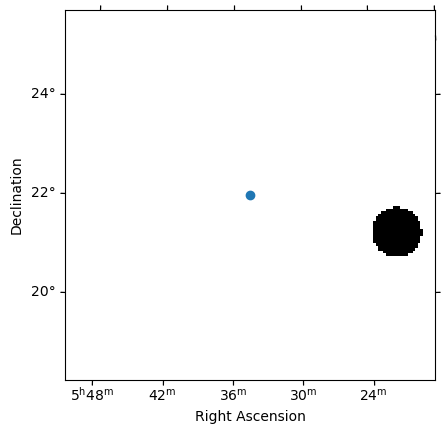

In [85]:
skydir = target_position.galactic
geom = WcsGeom.create(
    npix=(150, 150), binsz=0.05, skydir=skydir, proj="TAN", frame="icrs"
)

exclusion_mask = ~geom.region_mask([exclusion_region])
ax = exclusion_mask.plot()
ax.scatter(target_position.ra, target_position.dec, transform=ax.get_transform("icrs"), label="Crab Nebula")
plt.show()

Create a geometry using `RegionGeom`.

In [86]:
geom = RegionGeom.create(region=on_region, axes=[energy_axis])

Create an empty `SpectrumDataset` based on the defined geometry and true energy axis

In [87]:
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

Create the Maker instance that we are going to need for the data reduction.

`SpectrumDatasetMaker` computes the reduced IRFs (effective area, energy dispersion, and exposure) and fills each SpectrumDataset with the corresponding counts and instrument response information.

`ReflectedRegionsBackgroundMaker` estimates the background using the reflected-region method and extracts the OFF counts for each observation.

`SafeMaskMaker` defines the safe energy range and creates a mask that restricts the analysis to reliable reconstructed energies.

In [88]:
dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker(exclusion_mask=exclusion_mask)
safe_mask_maker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=10)

Run the data reduction loop. Order matters (dataset_maker, bkg, safe_mask)

In [89]:
datasets = Datasets()

for obs, obs_id in zip(observations, observations.ids):
    dataset = dataset_maker.run(dataset_empty.copy(name=obs_id), obs)
    dataset_on_off = bkg_maker.run(dataset, obs)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, obs)
    datasets.append(dataset_on_off)

print(datasets)

Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : 23523
  Instrument : HESS
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : 23526
  Instrument : HESS
  Models     : 

Dataset 2: 

  Type       : SpectrumDatasetOnOff
  Name       : 23559
  Instrument : HESS
  Models     : 

Dataset 3: 

  Type       : SpectrumDatasetOnOff
  Name       : 23592
  Instrument : HESS
  Models     : 




Parallel version of the reduction loop

```python
makers = [dataset_maker, bkg_maker, safe_mask_maker]  # the order matters
datasets_maker = DatasetsMaker(makers, stack_datasets=False, n_jobs=6)
datasets = datasets_maker.run(dataset_empty, observations)
```

Info table:

In [90]:
info_table = datasets.info_table(cumulative=True)

In [91]:
info_table

name,counts,excess,sqrt_ts,background,npred,npred_background,npred_signal,exposure_min,exposure_max,livetime,ontime,counts_rate,background_rate,excess_rate,n_bins,n_fit_bins,stat_type,stat_sum,counts_off,acceptance,acceptance_off,alpha
,,,,,,,,m2 s,m2 s,s,s,1 / s,1 / s,1 / s,,,,,,,,
str7,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,str5,float64,int64,float64,float64,float64
stacked,137,128.85714721679688,20.294993557896206,8.142857551574707,16.733334018521838,16.733334018521838,nan,261132.46875,812108608.0,1581.736764695497,1687.0000000000016,0.08661365345856023,0.0051480484827336635,0.08146560799046951,27,18,wstat,430.54947936469125,114,18.0,251.99998474121094,0.0714285746216774
stacked,276,257.78570556640625,28.191106280229125,18.21428680419922,35.40000147700309,35.40000147700309,nan,1219567.125,1524699136.0,3154.4235137812757,3369.9999999999964,0.08749617760398724,0.005774204612862956,0.08172197057249074,27,19,wstat,807.9727020988478,255,37.0,518.0,0.0714285746216774
stacked,403,378.177001953125,35.854967342750896,24.822982788085938,41.43887387416323,41.43887387416323,nan,1750019.0,2011274240.0,4732.546993609518,5056.000000000001,0.08515499170830876,0.005245163507431635,0.07990982497665365,27,19,wstat,1301.92807411124,559,56.0,1261.08935546875,0.04440605267882347
stacked,506,475.0770263671875,40.597777322169826,30.922983169555664,48.84134755831766,48.84134755831766,nan,1909606.875,2550689280.0,6313.811659421768,6741.999999999996,0.08014176337441471,0.004897672727283673,0.07524409215758837,27,19,wstat,1676.357442285647,803,74.0,1921.6126708984375,0.038509320467710495


Plot the reflected regions:

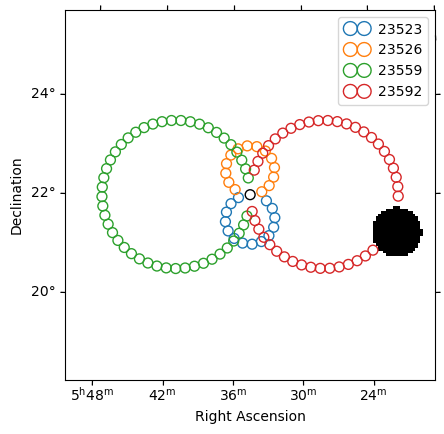

In [92]:
plt.figure()
ax = exclusion_mask.plot()
on_region.to_pixel(ax.wcs).plot(ax=ax, edgecolor="k")
plot_spectrum_datasets_off_regions(ax=ax, datasets=datasets)
plt.show()


Stack the dataset using `stack_reduce`.

In [93]:
stacked = datasets.stack_reduce(name="stacked")

Create a power-law using the `PowerLawSpectralModel`.

In [94]:
spectral_model = PowerLawSpectralModel(
    index=2, 
    amplitude=2e-11 * u.Unit("cm-2 s-1 TeV-1"), 
    reference=1*u.TeV
)

Create a `SkyModel`.

In [95]:
sky_model = SkyModel(spectral_model=spectral_model, name="Crab")

Fit the model to the stacked dataset.

In [96]:
stacked.models = sky_model

In [97]:
fit = Fit()
result = fit.run(datasets=stacked)

In [98]:
print(result)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 47
	total stat : 14.56

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [99]:
stacked.models

Plot the residuals:

<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals ((data - model) / sqrt(model))'>

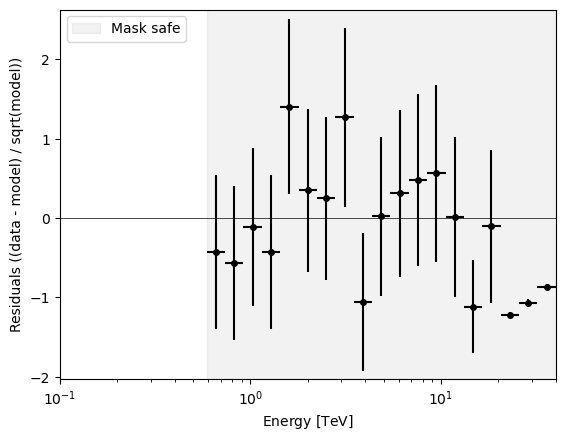

In [100]:
stacked.plot_residuals_spectral(method="diff/sqrt(model)")

or look at them together with the data to model fit using
`~gammapy.datasets.SpectrumDataset.plot_fit()`



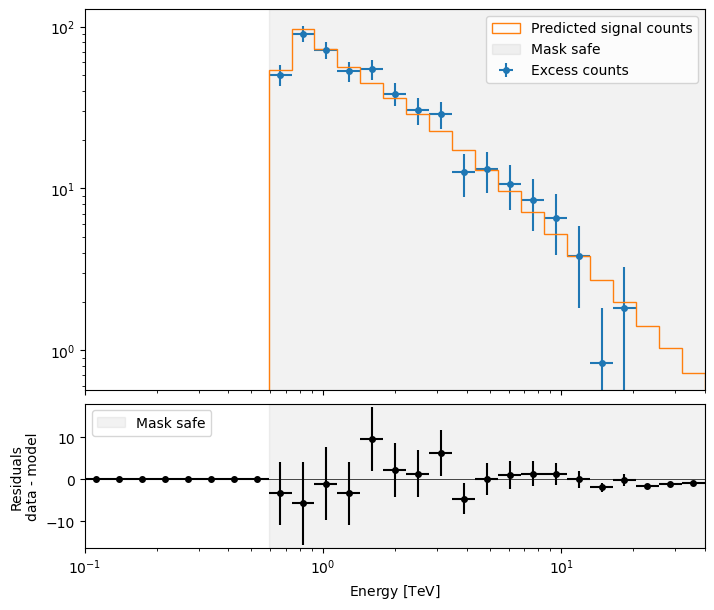

In [101]:
ax_spectrum, ax_residuals = stacked.plot_fit()

Check the likelihood profile of your fit parameters:

Text(0, 0.5, 'Delta TS')

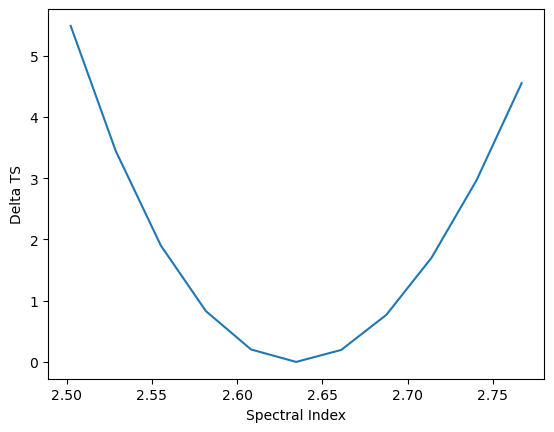

In [102]:
parameter = stacked.models.parameters['index']
profile = fit.stat_profile(stacked, parameter=parameter)
total_stat = result.total_stat

plt.plot(profile['Crab.spectral.index_scan'], profile['stat_scan']-total_stat)
plt.xlabel('Spectral Index')
plt.ylabel('Delta TS')

Extract flux points:

In [103]:
fp = FluxPointsEstimator(
    energy_edges=energy_axis.edges, 
    source="Crab", 
    selection_optional="all"
).run(datasets=stacked)

Plot the model and flux points.

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='e2dnde [$\\mathrm{erg\\,s^{-1}\\,cm^{-2}}$]'>

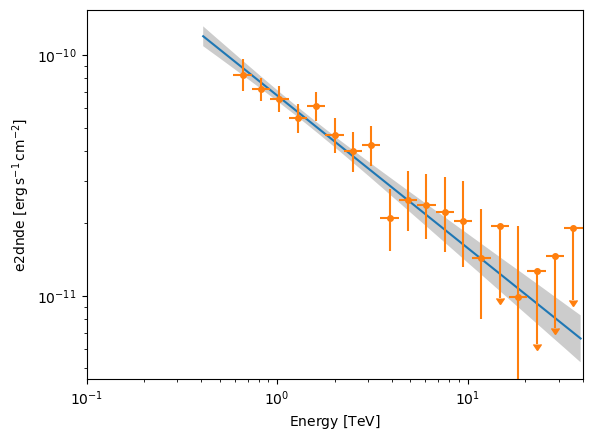

In [104]:
sed_type = "e2dnde"
energy_bounds = [0.4, 40]*u.TeV

stacked.models[0].spectral_model.plot(energy_bounds=energy_bounds, sed_type=sed_type, label="Best fit")
stacked.models[0].spectral_model.plot_error(energy_bounds=energy_bounds, sed_type=sed_type)
fp.plot(sed_type=sed_type, label="Flux Points")

#### Model significance

Exercise: Is a power-law the best model to describe the data? 

To answer this question, we propose to use a likelihood ratio test (see Jonathan lecture) test both a `LogParabolaSpectralModel` and an `ExpCutoffPowerLawSpectralModel`.

Are those two models nested models to a power-law respectively?

Can we apply Wilks' theorem? 

Knowing that the "total stat" of the fit result is $-2\ln(\mathcal{L})$, where $\mathcal{L}$ is the likelihood, compute the significance of the exponentially cutoff power-law and the log-parabola against the power-law. 

Can you do the same likelihood ratio test to distinguish the exponentially cutoff power-law and the log-parabola?

In [105]:
spectral_model_exp = ExpCutoffPowerLawSpectralModel(
    index=2, 
    amplitude=2e-11 * u.Unit("cm-2 s-1 TeV-1"), 
    reference=1*u.TeV,
    lambda_ = (1/10)/u.TeV,
)

In [106]:
sky_model_exp = SkyModel(spectral_model=spectral_model_exp, name="Crab exp")

In [107]:
stacked.models = sky_model_exp

In [108]:
fit = Fit()
result_exp = fit.run(datasets=stacked)

In [109]:
print(result_exp)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 94
	total stat : 8.84

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [110]:
stacked.models

<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals ((data - model) / sqrt(model))'>

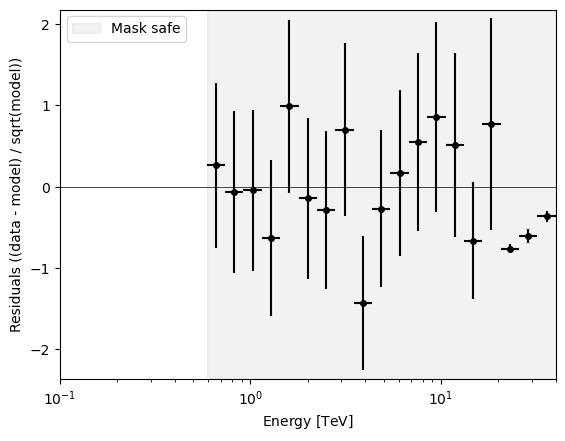

In [111]:
stacked.plot_residuals_spectral(method="diff/sqrt(model)")

In [112]:
h0 = result.optimize_result.total_stat
h1 = result_exp.optimize_result.total_stat
likelihood_ratio_ts = -(h1 - h0)
likelihood_ratio_ts

np.float64(5.719080210236127)

In [113]:
np.sqrt(likelihood_ratio_ts)

np.float64(2.3914598491791845)

## Alternative approach for evaluate nested models using Gammapy API
Alternatively, Gammapy also allows evaluating two nested models using [`gammapy.modeling.select_nested_models`](https://docs.gammapy.org/2.0/api/gammapy.modeling.select_nested_models.html)

If there is no cutoff (null hypothesis) then the spectral cutoff (`lambda`) is zero. So that is the parameter we input in this function along with the null value against we are hypothesis testing.

**Note:** This is useful for testing the significance of adding model components, such as a spectral cutoff or a source detection. It assumes the two models are nested — the null hypothesis is a special case of the alternative with fixed parameters.

In [114]:
result_nested_models = select_nested_models(
    stacked,
    parameters=[sky_model_exp.spectral_model.lambda_],
    null_values=[0],
    n_sigma=3
)
result_nested_models["ts"]

np.float64(5.719081484423466)

In [123]:
stacked.models

## Flux points estimation

In [42]:
fp_exp = FluxPointsEstimator(
    energy_edges=energy_axis.edges, 
    source="Crab exp", 
    selection_optional="all"
).run(datasets=stacked)

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


(0.4, 40)

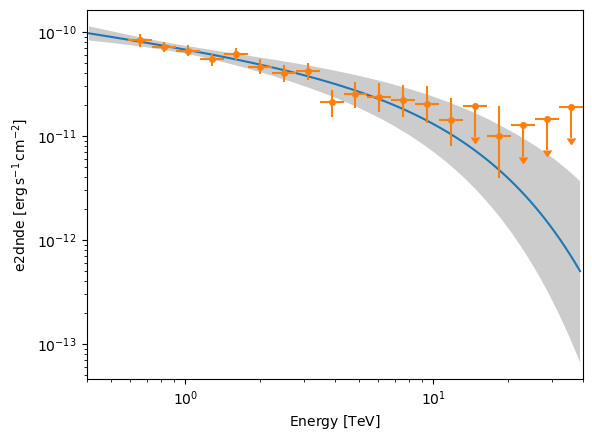

In [43]:
sed_type = "e2dnde"
energy_bounds = [0.4, 40]*u.TeV

stacked.models[0].spectral_model.plot(energy_bounds=energy_bounds, sed_type=sed_type, label="Best fit")
stacked.models[0].spectral_model.plot_error(energy_bounds=energy_bounds, sed_type=sed_type)
fp.plot(sed_type=sed_type, label="Flux Points")

plt.xlim(0.4, 40)

In [44]:
spectral_model_log = LogParabolaSpectralModel(
    alpha=2, 
    amplitude=2e-11 * u.Unit("cm-2 s-1 TeV-1"), 
    reference=1*u.TeV,
    beta=1,
)

In [45]:
sky_model_log = SkyModel(spectral_model=spectral_model_log, name="Crab log")

In [46]:
stacked.models = sky_model_log

In [47]:
fit = Fit()
result_log = fit.run(datasets=stacked)

In [48]:
print(result_exp)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 94
	total stat : 8.84

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [49]:
stacked.models

<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals ((data - model) / sqrt(model))'>

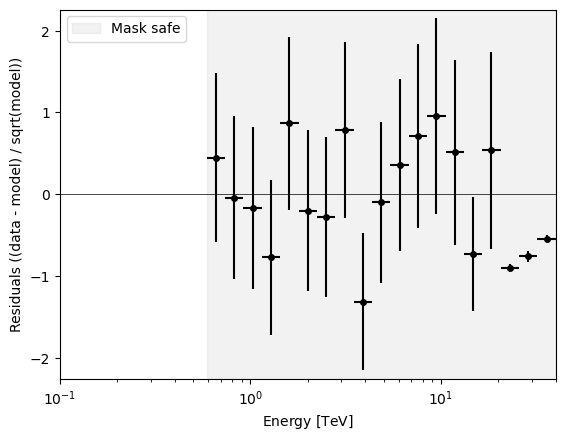

In [50]:
stacked.plot_residuals_spectral(method="diff/sqrt(model)")

In [51]:
h0 = result.optimize_result.total_stat
h1 = result_log.optimize_result.total_stat
likelihood_ratio_ts = -(h1 - h0)

In [52]:
np.sqrt(likelihood_ratio_ts)

np.float64(2.0950765860819565)

In [53]:
fp_log = FluxPointsEstimator(
     energy_edges=energy_axis.edges, 
    source="Crab log", 
    selection_optional="all"
).run(datasets=stacked)

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


(0.4, 40)

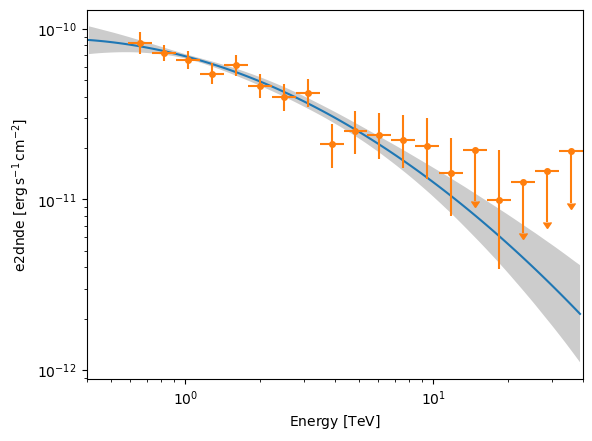

In [54]:
sed_type = "e2dnde"
energy_bounds = [0.4, 40]*u.TeV

stacked.models[0].spectral_model.plot(energy_bounds=energy_bounds, sed_type=sed_type, label="Best fit")
stacked.models[0].spectral_model.plot_error(energy_bounds=energy_bounds, sed_type=sed_type)
fp.plot(sed_type=sed_type, label="Flux Points")

plt.xlim(0.4, 40)

### 1.2 Point-like IRFs

#### Redo the Crab nebulae analysis using "Point-like" observations from MAGIC

For that you will have to get the data from `$GAMMAPY_DATA/magic/rad_max/data/`. 

To get the observations, `required_irf="point-like"` has to be passed to `DataStore.get_observations`.

Also note that MAGIC energy threshold is lower that H.E.S.S.. You can start your dataset reco energy axis at 50 GeV. Of course, you will have to adapt you true energy in consequences.

Finally, using "point-like" IRFs, it is better to use Wobble regions for the off counts. You can define region_finder of `ReflectedRegionsBackgroundMaker` to `ReflectedRegionsBackgroundMaker`. 

In [55]:
data_store_magic = DataStore.from_dir("$GAMMAPY_DATA/magic/rad_max/data/")

In [56]:
observations = data_store_magic.get_observations(required_irf="point-like")

In [57]:
on_region = PointSkyRegion(target_position)

In [58]:
energy_axis = MapAxis.from_energy_bounds(
    40, 2e4, nbin=5, per_decade=True, unit="GeV", name="energy"
)
energy_axis_true = MapAxis.from_energy_bounds(
    10, 1e5, nbin=10, per_decade=True, unit="GeV", name="energy_true"
)

In [59]:
geom = RegionGeom.create(region=on_region, axes=[energy_axis])

dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

dataset_maker = SpectrumDatasetMaker(
    selection=["counts", "exposure", "edisp"]
)

region_finder = WobbleRegionsFinder(n_off_regions=3)
bkg_maker = ReflectedRegionsBackgroundMaker(region_finder=region_finder)

safe_mask_maker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=10)

In [60]:
datasets = Datasets()

for obs, obs_id in zip(observations, observations.ids):
    dataset = dataset_maker.run(dataset_empty.copy(name=obs_id), obs)
    dataset_on_off = bkg_maker.run(dataset, obs)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, obs)
    datasets.append(dataset_on_off)

print(datasets)

'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.


Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : 5029747
  Instrument : Unknown
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : 5029748
  Instrument : Unknown
  Models     : 




In [61]:
stacked_magic = datasets.stack_reduce(name="stacked")

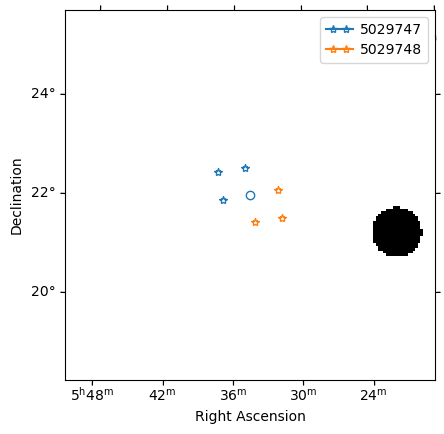

In [62]:
plt.figure()
ax = exclusion_mask.plot()
on_region.to_pixel(ax.wcs).plot(ax=ax)
plot_spectrum_datasets_off_regions(ax=ax, datasets=datasets)
plt.show()

In [63]:
spectral_model_exp = ExpCutoffPowerLawSpectralModel(
    index=2, 
    amplitude=2e-11 * u.Unit("cm-2 s-1 TeV-1"), 
    reference=1*u.TeV,
    lambda_ = (1/10)/u.TeV,
)

In [64]:
sky_model_exp = SkyModel(spectral_model=spectral_model_exp, name="Crab exp")

In [65]:
stacked_magic.models = sky_model_exp

In [66]:
for d in datasets:
    d.mask_fit = dataset.counts.geom.energy_mask(20*u.GeV, 20*u.TeV)

In [67]:
fit = Fit()
result_exp = fit.run(datasets=stacked_magic)

In [68]:
print(result_exp)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 154
	total stat : 6.81

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [69]:
print(stacked_magic.models)

DatasetModels

Component 0: SkyModel

  Name                      : Crab exp
  Datasets names            : None
  Spectral model type       : ExpCutoffPowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      2.029   +/-    0.10             
    amplitude                     :   6.51e-11   +/- 1.2e-11 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         
    lambda_                       :      0.350   +/-    0.14 1 / TeV     
    alpha                 (frozen):      1.000                   




<Axes: xlabel='Energy [$\\mathrm{GeV}$]', ylabel='Residuals ((data - model) / sqrt(model))'>

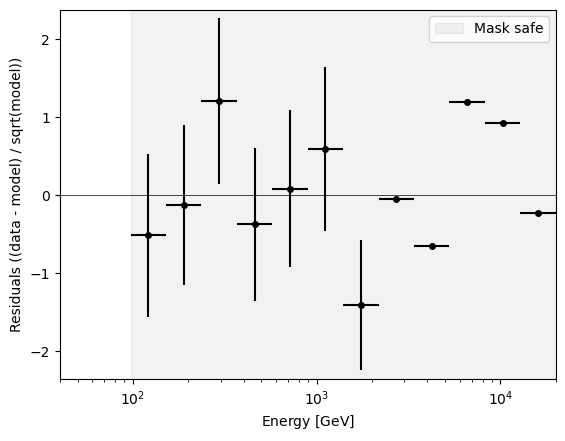

In [70]:
stacked_magic.plot_residuals_spectral(method="diff/sqrt(model)")

In [71]:
fp_exp = FluxPointsEstimator(
     energy_edges=energy_axis.edges, 
    source="Crab exp", 
    selection_optional="all"
).run(datasets=stacked_magic)

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


(2e-12, 2e-10)

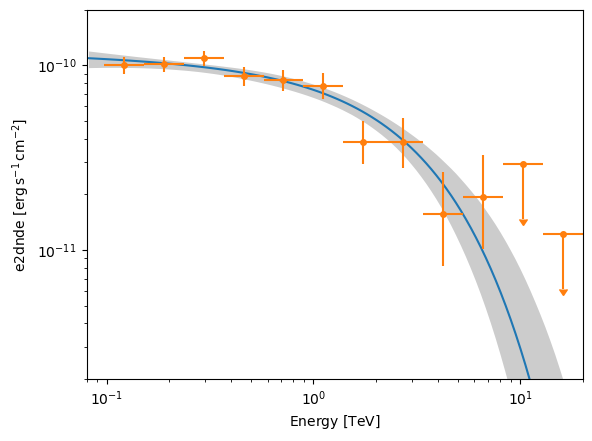

In [72]:
sed_type = "e2dnde"
energy_bounds = [0.08, 20]*u.TeV

stacked_magic.models[0].spectral_model.plot(energy_bounds=energy_bounds, sed_type=sed_type, label="Best fit")
stacked_magic.models[0].spectral_model.plot_error(energy_bounds=energy_bounds, sed_type=sed_type)
fp_exp.plot(sed_type=sed_type, label="Flux Points")

plt.xlim(0.08, 20)
plt.ylim(2e-12, 2e-10)